In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("/home/mersad/protBuild")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
from ml.src.training.dataset.protein_dataset import ProteinTextDataset, make_collate_fn
from ml.src.training.trainer.train import train_model_protein2text
from transformers import AutoModelForCausalLM, AutoTokenizer, AutoModel, AutoConfig
from ml.src.models.text2Protein.text2prot import Text2Prot
from ml.src.inference.sequence_generator import predict_protein_sequence
from ml.src.training.evaluator.evaluate import evaluate_protein2text
from torch.utils.data import DataLoader
from multiprocessing import Array
import pandas as pd
import random
import torch
import json
import math


In [ ]:
pretrained_protein_model_name = 'nferruz/ProtGPT2'
pretrained_text_model_name = 'microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext'


In [4]:
protein_tokenizer = AutoTokenizer.from_pretrained(pretrained_protein_model_name, trust_remote_code=True)
text_tokenizer = AutoTokenizer.from_pretrained(pretrained_text_model_name, trust_remote_code=True)

config.json:   0%|          | 0.00/815 [00:00<?, ?B/s]

In [5]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
# device = 'cpu'
text_model = AutoModel.from_pretrained(pretrained_text_model_name, trust_remote_code=True)
protein_model_config = AutoConfig.from_pretrained(pretrained_protein_model_name, add_cross_attention=True)
protein_model = AutoModelForCausalLM.from_pretrained(pretrained_protein_model_name, trust_remote_code=True, config=protein_model_config)

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: NeuML/biomedbert-small
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.34GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/178 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/171 [00:00<?, ?B/s]

In [6]:
protein_model.config.max_position_embeddings


512

In [7]:
text_model.config.max_position_embeddings

512

In [8]:
protein_tokenizer.SPECIAL_TOKENS_ATTRIBUTES

['bos_token',
 'eos_token',
 'unk_token',
 'sep_token',
 'pad_token',
 'cls_token',
 'mask_token']

In [9]:
text_tokenizer.SPECIAL_TOKENS_ATTRIBUTES

['bos_token',
 'eos_token',
 'unk_token',
 'sep_token',
 'pad_token',
 'cls_token',
 'mask_token']

In [10]:
print(protein_tokenizer.pad_token_id)
print(protein_tokenizer.pad_token)

print(text_tokenizer.pad_token_id)
print(text_tokenizer.pad_token)

0
<pad>
0
[PAD]


In [11]:
if protein_tokenizer.pad_token is None:
    protein_tokenizer.pad_token = protein_tokenizer.eos_token
if text_tokenizer.pad_token is None:
    text_tokenizer.pad_token = text_tokenizer.eos_token

protein_pad_id = protein_tokenizer.pad_token_id
text_pad_id = text_tokenizer.pad_token_id

In [12]:
num_workers=1
train_position_array = Array("Q", [0] * num_workers)
train_idx_array = Array("Q", [0] * num_workers)

In [13]:
train_dataset = ProteinTextDataset(
    PROJECT_ROOT / "ml/datasets/prot2text_train.jsonl",
    protein_tokenizer,
    text_tokenizer,
    1024,
    256,
    position_array=train_position_array,
    idx_array=train_idx_array,
)


val_dataset = ProteinTextDataset(
    PROJECT_ROOT / "ml/datasets/prot2text_val.jsonl",
    protein_tokenizer,
    text_tokenizer,
    1024,
    256,   
)


In [14]:
collate_fn = make_collate_fn(
    protein_pad_id=protein_pad_id,
    text_pad_id=text_pad_id,
    ignore_index=-100,
    model_type='t2p'
)

In [15]:
val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    collate_fn=collate_fn,
    num_workers=1,
    pin_memory=True,
    persistent_workers=True,
)


In [16]:
input_dim = text_model.config.hidden_size
output_dim = protein_model.config.hidden_size

In [17]:

model = Text2Prot(protein_model, text_model, 
                  input_dim=input_dim, hidden_dim=output_dim*2,
                    output_dim=output_dim, dropout=0.1,
                      bias=False)

In [18]:
for param in model.protein_model.parameters():
    param.requires_grad = False

for name, param in model.protein_model.named_parameters():
    if "crossattention" in name or "ln_cross_attn" in name:
        param.requires_grad = True

for param in model.projection.parameters():
    param.requires_grad = True

for param in model.norm.parameters():
    param.requires_grad = True

for param in model.llm_model.parameters():
    param.requires_grad = False

print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Trainable parameters: 2884608


In [19]:
print("Model type:", protein_model_config.model_type)
print("Architecture:", protein_model_config.architectures)
print("Has add_cross_attention:",
      hasattr(protein_model_config, "add_cross_attention"))
print("Cross attention enabled:",
      getattr(protein_model_config, "add_cross_attention", False))
print("Is encoder-decoder:",
      protein_model_config.is_encoder_decoder)

Model type: gemma2
Architecture: ['Gemma2ForCausalLM']
Has add_cross_attention: False
Cross attention enabled: False
Is encoder-decoder: False


In [20]:
optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=1e-4,
    weight_decay=0.01,
)

num_samples = 421_626
batch_size = 1
num_epochs = 5

steps_per_epoch = math.ceil(num_samples / batch_size)
total_steps = steps_per_epoch * num_epochs
warmup_steps = 20_000
min_lr_ratio = 1e-6 / 1e-4

def lr_lambda(current_step):
    if current_step < warmup_steps:
        return float(current_step + 1) / warmup_steps
    progress = (current_step - warmup_steps) / (total_steps - warmup_steps)

    cosine_decay = 0.5 * (1.0 + math.cos(math.pi * progress))

    return min_lr_ratio + (1.0 - min_lr_ratio) * cosine_decay

scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lr_lambda
)


In [21]:
metrics_history = train_model_protein2text(model=model, tokenizer=protein_tokenizer, train_dataset=train_dataset,
                                            val_loader=val_loader, optimizer=optimizer, scheduler=scheduler, device=device,
                                            num_epochs=num_epochs, eval_freq=100000, eval_iter=2000, train_position_array=train_position_array, 
                                            train_idx_array=train_idx_array, checkpoint_iter=250, collate_fn=collate_fn, checkpoint_path='./checkpoints', 
                                            save_file_name='text2prot_checkpoint.pt', num_workers=num_workers, batch_size=batch_size, max_new_tokens=1024, model_type='t2p')

No checkpoint found.


Epoch 1/5: 0batch [00:00, ?batch/s]


RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

In [ ]:
torch.save(model.state_dict(), PROJECT_ROOT/'ml/notebooks/text2prot_model.pth')

In [ ]:
df = pd.DataFrame.from_dict(metrics_history, orient="index")
df.index.name = "step"
df.to_csv(PROJECT_ROOT/'ml/notebooks/training_history_text2prot.csv')

## Load Model


In [ ]:
model.load_state_dict(torch.load(PROJECT_ROOT/'ml/notebooks/text2prot_model.pth'))
model.to(device)

Prot2Text(
  (protein_model): EsmModel(
    (embeddings): EsmEmbeddings(
      (word_embeddings): Embedding(33, 320, padding_idx=1)
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (rotary_embeddings): EsmRotaryEmbedding()
    (encoder): EsmEncoder(
      (layer): ModuleList(
        (0-5): 6 x EsmLayer(
          (attention): EsmAttention(
            (self): EsmSelfAttention(
              (query): Linear(in_features=320, out_features=320, bias=True)
              (key): Linear(in_features=320, out_features=320, bias=True)
              (value): Linear(in_features=320, out_features=320, bias=True)
            )
            (output): EsmSelfOutput(
              (dense): Linear(in_features=320, out_features=320, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (LayerNorm): LayerNorm((320,), eps=1e-05, elementwise_affine=True, bias=True)
          )
          (intermediate): EsmIntermediate(
            (dense): Linear(in_features=320,

In [ ]:
test_dataset = ProteinTextDataset(
    PROJECT_ROOT / "ml/datasets/prot2text_test.jsonl",
    protein_tokenizer,
    text_tokenizer,
    1024,
    256,   
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    collate_fn=collate_fn,
    num_workers=1,
    pin_memory=True,
    persistent_workers=True,
)

In [ ]:
model.eval()
batch_idx = 0
num_batches = 50

with torch.no_grad():
    for batch in test_loader:
        if batch_idx >= num_batches:
            break

        protein_ids = batch["protein_ids"].to(device)
        text_ids = batch["text_idxs"]

        print(f"\nBatch: {batch_idx + 1}")

        for i in range(text_ids.size(0)):

            sequence = text_tokenizer.decode(
                text_ids[i],
                skip_special_tokens=True,
            )

            valid_protein_ids = protein_ids[i][
                batch["protein_attention_mask"][i].bool()
            ]

            reference = protein_tokenizer.decode(
                valid_protein_ids,
                skip_special_tokens=True,
            )
                
            prediction = predict_protein_sequence(
                model=model,
                protein_tokenizer=protein_tokenizer,
                text_tokenizer=text_tokenizer,
                sequence=sequence,
            )

            print(f"\nSequence: {sequence}")
            print(f"Reference: {reference}")
            print(f"Prediction: {prediction}")
            print("-" * 80)

        batch_idx += 1


Batch: 1

Sequence: M G A Y K Y M Q K L W R K K Q S N V M R F L L R V R C W Q Y R Q L S S L H R A P R P T R P D K A R R L G Y K A K Q G Y V I Y R I R V R R G G R K R P V P K G A T Y G K P V H H G V N Q I K F A R S L Q S V A E E R A G R H C G G L R V L N S Y W V G E D S T Y K F F E V I L I D T F H K A I R R N P D T Q W I T K A V H K H R E M R G L T S A G K K S R G L G K G H K F H L T I G G S R R A A W K R R N T L Q L H R Y R
Reference: This protein Component of the large ribosomal subunit. The ribosome is a large ribonucleoprotein complex responsible for the synthesis of proteins in the cell. It is located in Cytoplasm. It Belongs to the eukaryotic ribosomal protein eL15 family.
Prediction: This protein Component of the large ribosomal subunit. The ribosome is a large ribonucleoprotein complex responsible for the synthesis of proteins in the cell. It is located in Cytoplasm. It Belongs to the eukaryotic ribosomal protein eL15 family.
----------------------------------------------------

In [ ]:
results, predictions, references = evaluate_protein2text(
    model=model,
    test_loader=test_loader,
    text_tokenizer=text_tokenizer,
    device=device,
    max_new_tokens=1024,
    bert_batch_size=8,
    bert_model='facebook/esm2_t6_8M_UR50D',
)

Generating predictions: 2929it [1:45:40,  2.16s/it]



Total evaluated samples: 23425


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  433MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  433MB            

model.safetensors: downloading bytes:           |  0.00B            

num_samples: 23425
bleu-4: 0.6085
rouge1: 0.7703
rouge2: 0.7304
rougeL: 0.7631
bertscore_precision: 0.9305
bertscore_recall: 0.9094
bertscore_f1: 0.9182


In [ ]:
df = pd.DataFrame({
    "reference": references,
    "prediction": predictions,
})

df.to_csv(PROJECT_ROOT / "ml/datasets/text2prot_test_predictions.csv", index=False)

pd.DataFrame([results]).to_csv(
    PROJECT_ROOT / "ml/datasets/text2prot_test_metrics.csv",
    index=False,
)

# Plotting Results


In [ ]:
from matplotlib.ticker import MultipleLocator
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
df = pd.read_csv(PROJECT_ROOT/'ml/notebooks/training_history_text2prot.csv', usecols=['step',
                                                                            'train_loss',
                                                                            'val_loss',
                                                                            'train_perplexity',
                                                                            'val_perplexity',
                                                                            'bleu',
                                                                            'rouge1',
                                                                            'rouge2',
                                                                            'rougeL',]
)
steps = df.step
df.head()

,step,train_loss,val_loss,train_perplexity,val_perplexity,bleu,rouge1,rouge2,rougeL
0,step-100000,1.143107,0.749829,3.136498,2.116637,0.286254,0.528827,0.426830,0.515428
1,step-200000,0.732736,0.632064,2.080766,1.881490,0.342972,0.595970,0.509979,0.585422
2,step-300000,0.648440,0.566734,1.912556,1.762502,0.366353,0.620206,0.546945,0.611168
3,step-400000,0.600547,0.529332,1.823115,1.697798,0.399954,0.639807,0.566967,0.629564
4,step-500000,0.534699,0.508526,1.706934,1.662839,0.396425,0.646559,0.581364,0.638035


In [ ]:
def plot(x_data, y_data, title, y2_data=None, xlabel="Steps", ylabel="Value",
         ticks_scale=0.1, figsize=(12, 5), grid=True, marker=None, label1="Training",
         label2="Validation", save_path=None):

    fig, ax = plt.subplots(figsize=figsize)

    ax.plot(x_data, y_data, marker=marker, linewidth=1.5, label=label1)
    if y2_data is not None:
        ax.plot(x_data, y2_data, marker=marker, linewidth=1.5, label=label2)
        ax.legend()
        
    ax.set_title(title, fontsize=14, pad=12)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    ax.yaxis.set_major_locator(MultipleLocator(ticks_scale))
    if grid:
        ax.grid(True, which='major', linestyle='--', alpha=0.5)

    ax.tick_params(axis='x', labelrotation=90)
    fig.tight_layout()

    if save_path:
        fig.savefig(save_path/f'{title}.png', dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

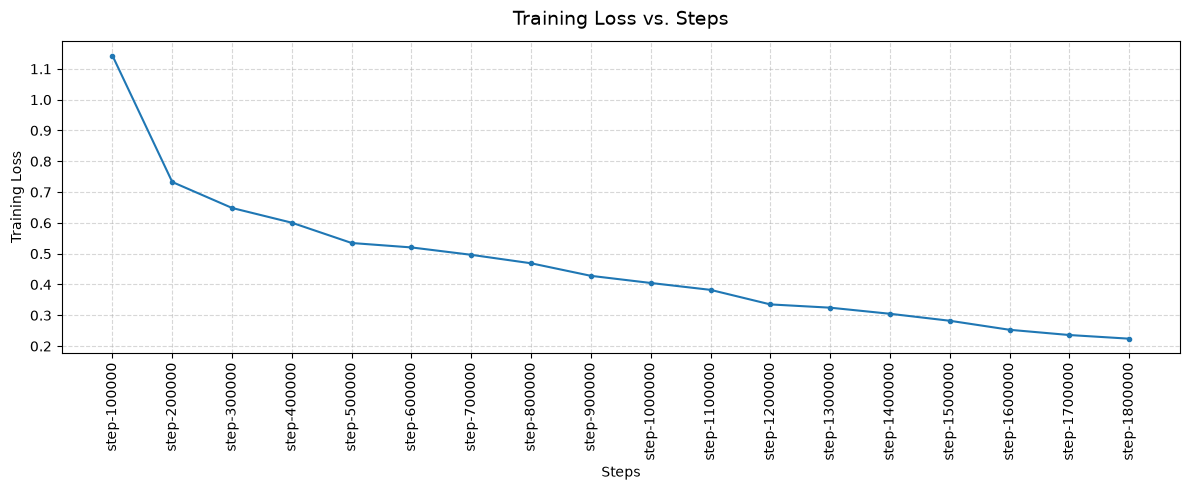

In [ ]:
plot(steps, df.train_loss, title="Training Loss vs. Steps", ylabel='Training Loss', marker='.', save_path=PROJECT_ROOT/'ml/notebooks/plots/')

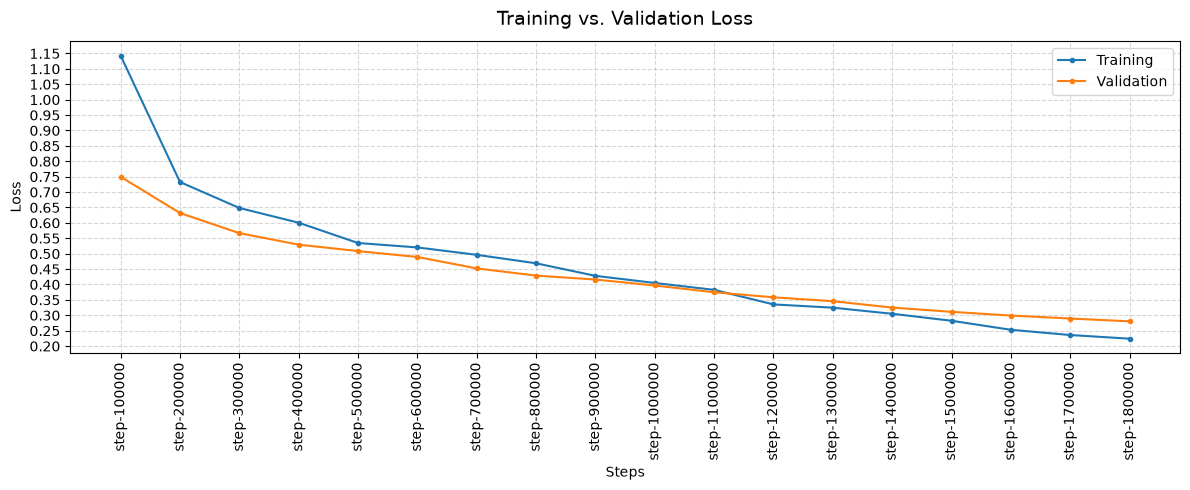

In [ ]:
plot(steps, df.train_loss, y2_data=df.val_loss, title="Training vs. Validation Loss", ylabel='Loss', marker='.', ticks_scale=0.05, save_path=PROJECT_ROOT/'ml/notebooks/plots/')

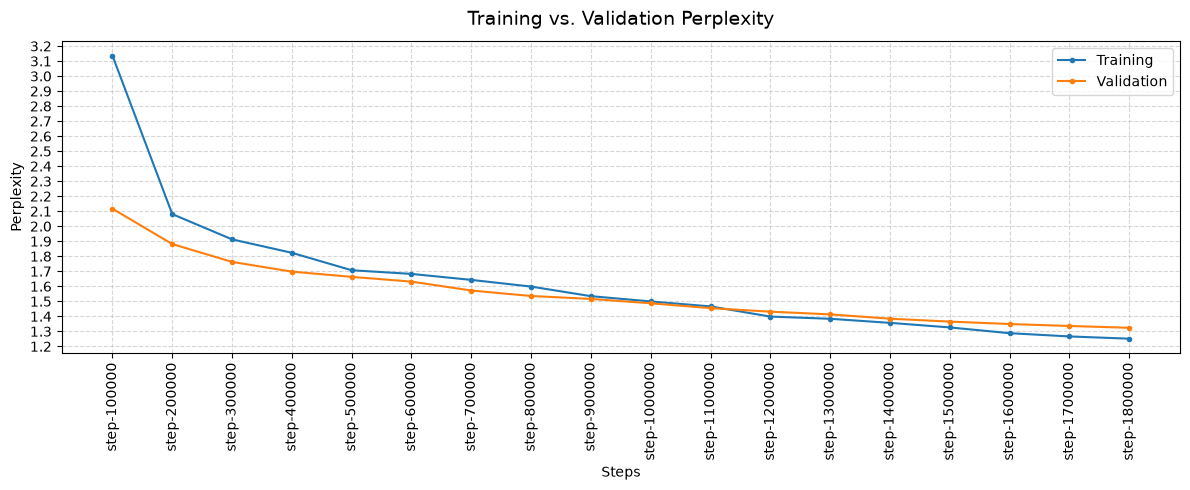

In [ ]:
plot(steps, df.train_perplexity, y2_data=df.val_perplexity, title="Training vs. Validation Perplexity", ylabel='Perplexity', marker='.', ticks_scale=0.1, save_path=PROJECT_ROOT/'ml/notebooks/plots/')


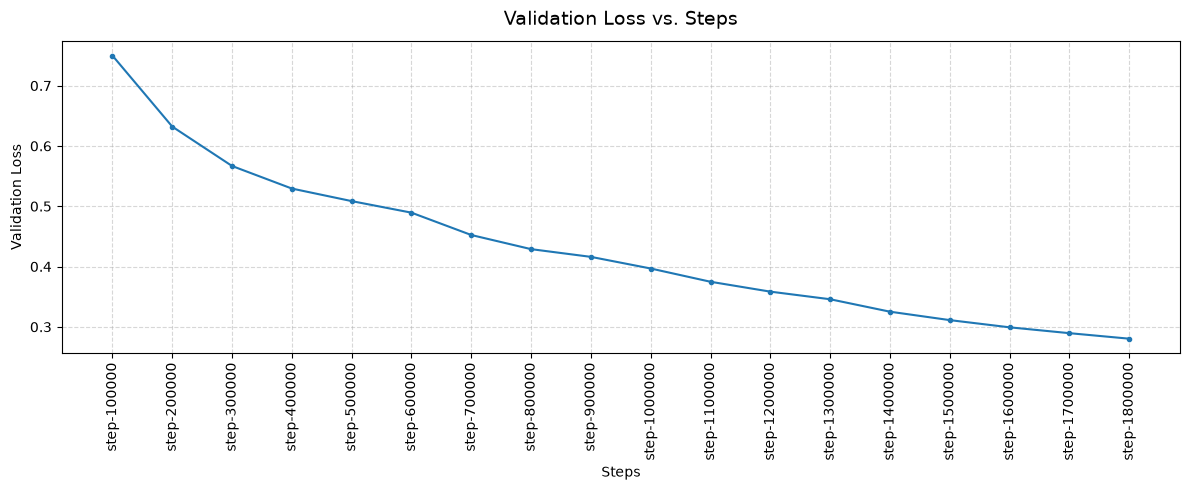

In [ ]:
plot(steps, df.val_loss, title="Validation Loss vs. Steps", ylabel='Validation Loss', marker='.', save_path=PROJECT_ROOT/'ml/notebooks/plots/')


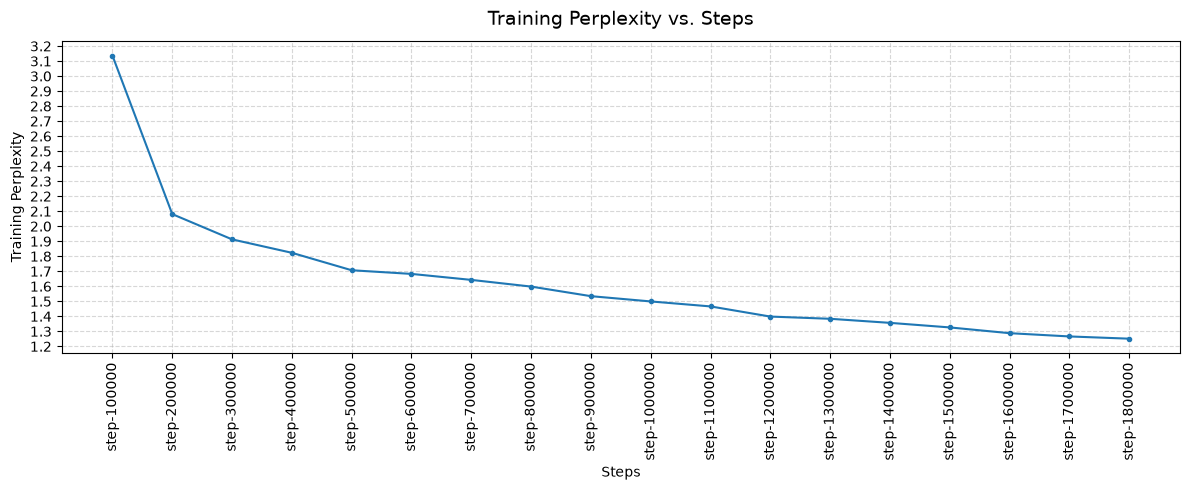

In [ ]:
plot(steps, df.train_perplexity, title="Training Perplexity vs. Steps", ylabel='Training Perplexity', marker='.', save_path=PROJECT_ROOT/'ml/notebooks/plots/')


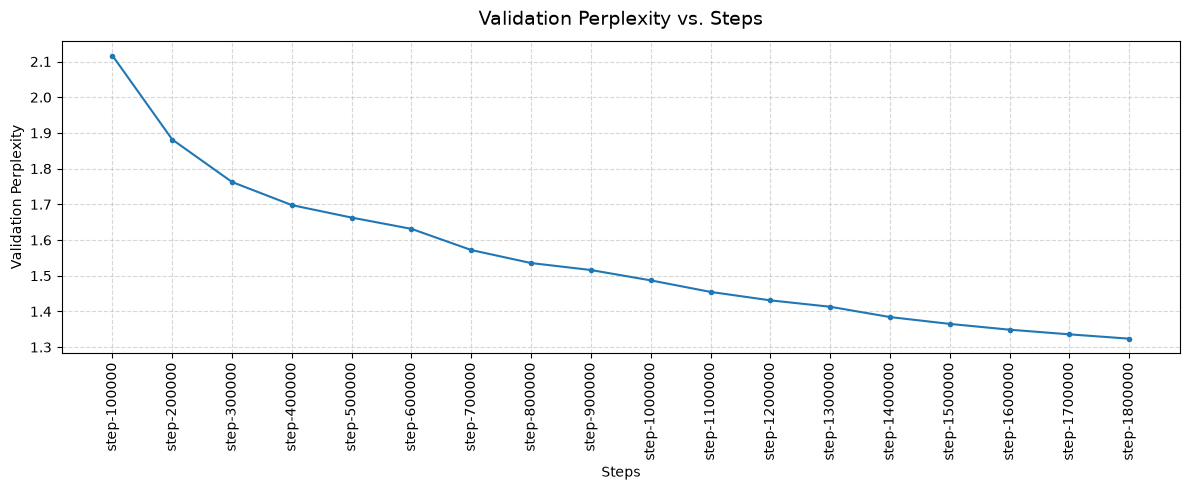

In [ ]:
plot(steps, df.val_perplexity, title="Validation Perplexity vs. Steps", ylabel='Validation Perplexity', marker='.', save_path=PROJECT_ROOT/'ml/notebooks/plots/')


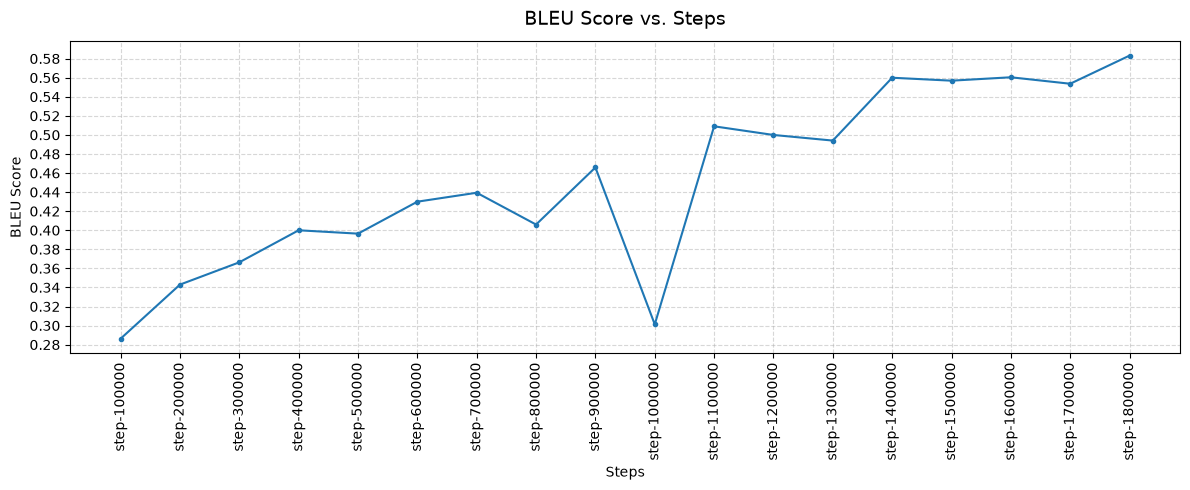

In [ ]:
plot(steps, df.bleu, title="BLEU Score vs. Steps", ylabel='BLEU Score', marker='.', ticks_scale=0.02, save_path=PROJECT_ROOT/'ml/notebooks/plots/')

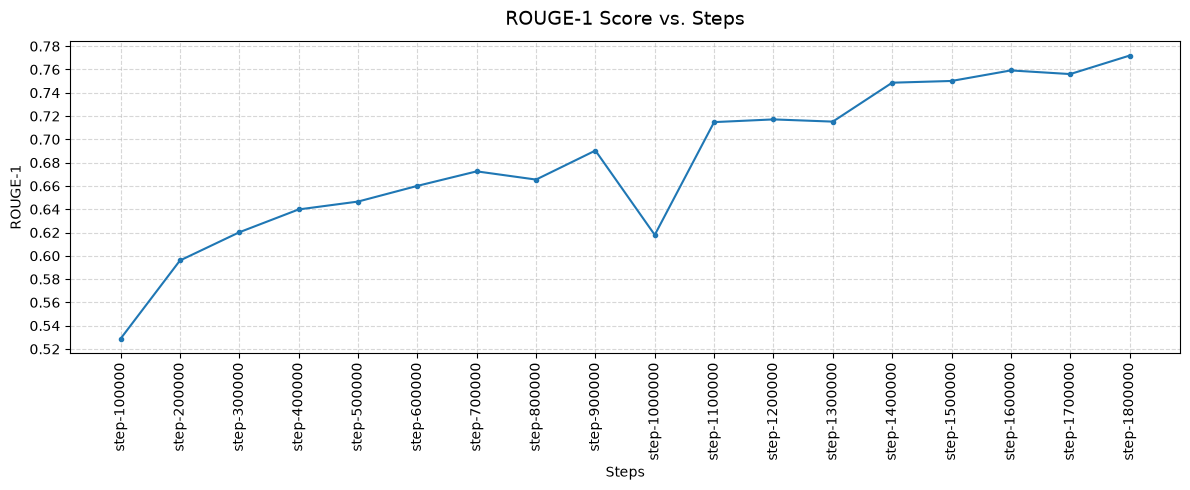

In [ ]:
plot(steps, df.rouge1, title="ROUGE-1 Score vs. Steps", ylabel='ROUGE-1', marker='.', ticks_scale=0.02, save_path=PROJECT_ROOT/'ml/notebooks/plots/')


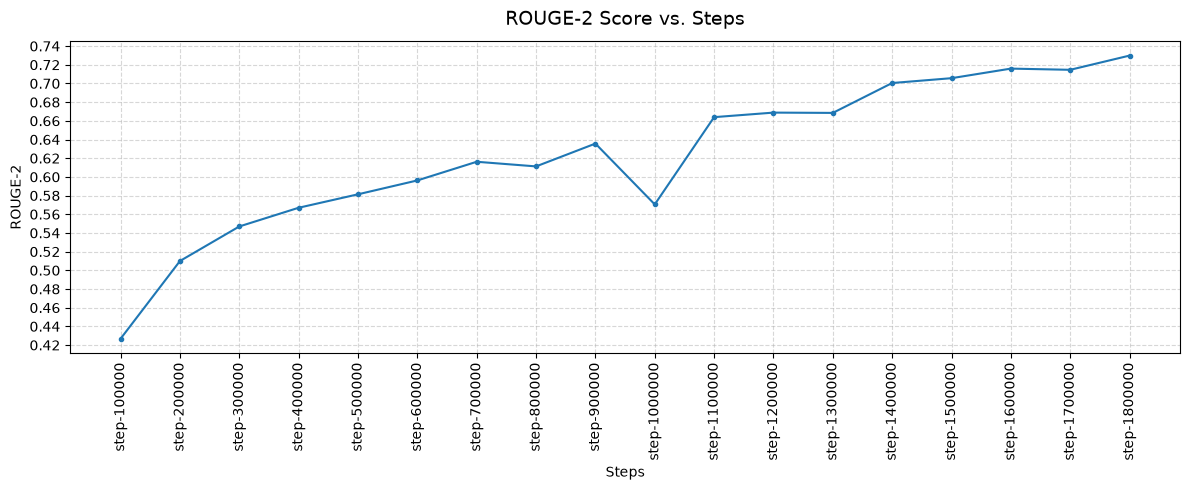

In [ ]:
plot(steps, df.rouge2, title="ROUGE-2 Score vs. Steps", ylabel='ROUGE-2', marker='.', ticks_scale=0.02, save_path=PROJECT_ROOT/'ml/notebooks/plots/')


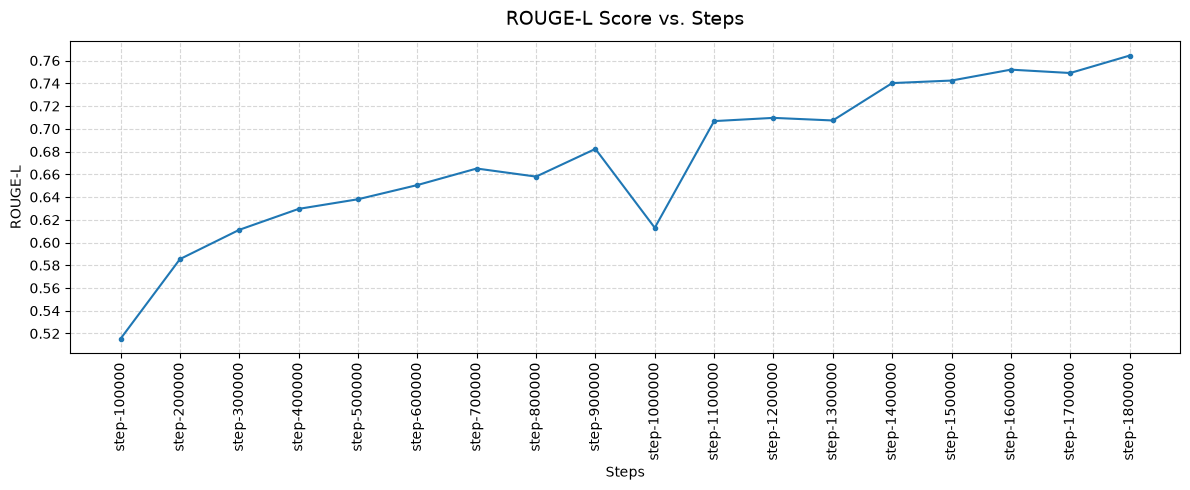

In [ ]:
plot(steps, df.rougeL, title="ROUGE-L Score vs. Steps", ylabel='ROUGE-L', marker='.', ticks_scale=0.02, save_path=PROJECT_ROOT/'ml/notebooks/plots/')


In [ ]:
metrics = (
    pd.read_csv(PROJECT_ROOT / "ml/datasets/text2prot_test_metrics.csv")
    .iloc[0]
    .to_dict()
)

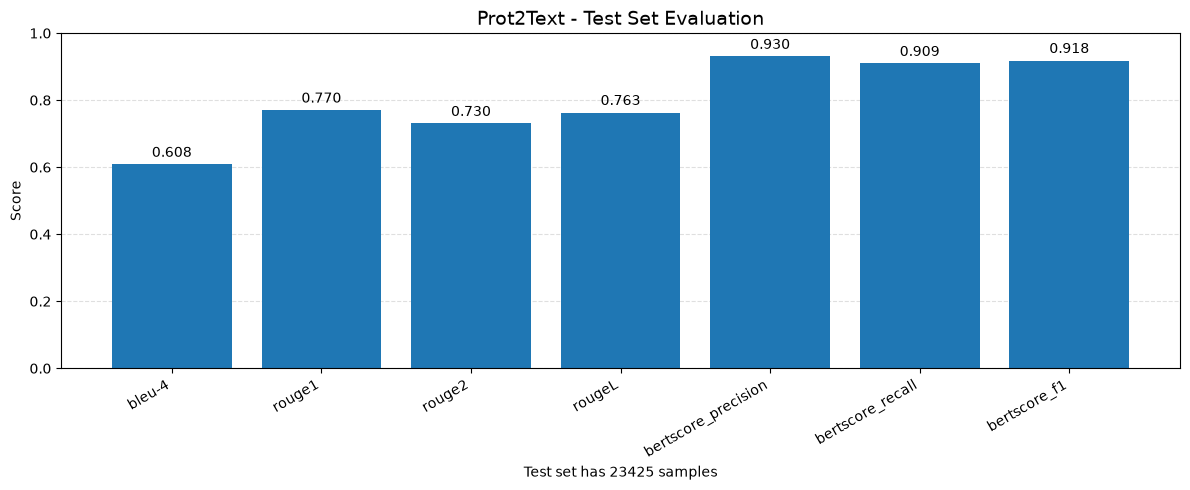

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.set_xlabel(f"Test set has {int(metrics['num_samples'])} samples")
del metrics['num_samples']
bars = ax.bar(metrics.keys(), metrics.values())

ax.set_title("Prot2Text - Test Set Evaluation", fontsize=14)
ax.set_ylabel("Score")

ax.set_ylim(0, 1)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

ax.bar_label(bars, fmt="%.3f", padding=3)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
fig.savefig(PROJECT_ROOT/'ml/notebooks/plots/Test Set Evaluation.png', dpi=300, bbox_inches="tight")
plt.show()